In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import umap

## Helper Functions

In [2]:
def catmullrom(p0, p1, p2, p3, t):
    t2 = t * t
    t3 = t2 * t
    return 0.5 *((2 * p1) + 
    (-p0 + p2) * t + 
    (2*p0 - 5*p1 + 4*p2 - p3) * t2 + 
    (-p0 + 3*p1- 3*p2 + p3) * t3)


def interpolate_waveform(input_array, output_n_points):
    input_array = np.asarray(input_array)
    n = input_array.shape[-1]

    pos = np.arange(output_n_points) * (n / output_n_points)

    P1 = np.floor(pos).astype(int)
    P2 = P1 + 1
    P0 = P1 - 1
    P3 = P2 + 1

    t = pos - P1

    p0 = input_array[:, P0 % n]
    p1 = input_array[:, P1 % n]
    p2 = input_array[:, P2 % n]
    p3 = input_array[:, P3 % n]

    return catmullrom(p0, p1, p2, p3, t[None, :])

## UMAP visualization of read count over 48 hrs

/home/yeti1t3y/anaconda3/envs/arabidopsispiano/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


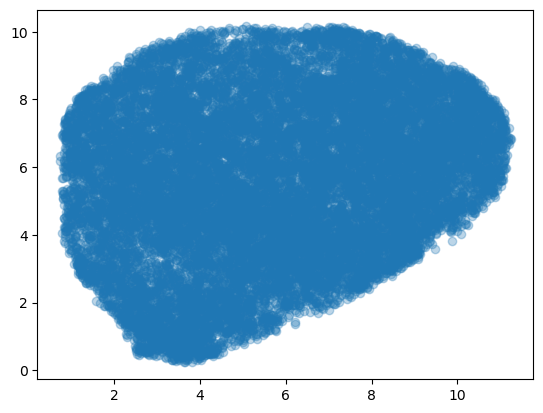

In [3]:
dat = pd.read_csv("../Processed_Data/VST.csv")
dat = dat.drop(columns=["GeneID"])
X = dat.to_numpy()
X = (X - X.mean(1, keepdims=True)) / X.std(1, keepdims=True)
reducer = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.25, random_state=42, metric="cosine")
emb_umap = reducer.fit_transform(X)
plt.scatter(
    emb_umap[:, 0],
    emb_umap[:, 1],
    alpha = 0.3,
)

## Interpolate then Max Abs Scaling

Catmullrom interpolation overshoots existing min and max sometimes so normalization to between -1 and 1 should happen after interpolation.

In [4]:
df = pd.read_csv("../Processed_Data/Normalized_counts.csv")
X = df.drop(columns=['GeneID', 'log_TPM']).to_numpy()
interpolated = interpolate_waveform(X, 2048)

#mean center
interpolated = interpolated - interpolated.mean(axis=1, keepdims=True)
interpolated = interpolated / abs(interpolated).max(axis=1, keepdims=True)

## FFT on Max-Abs Scaled waveforms

In [5]:
specs = np.abs(np.fft.rfft(interpolated, axis = 1))

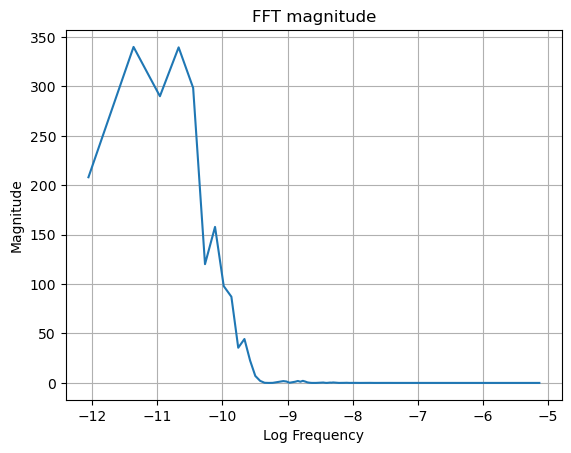

In [6]:
freqs = np.fft.rfftfreq(2048, d=84.375)  # d = 1 / (samples/second); bin 0 is DC (freq=0)
plt.plot(np.log(freqs[1:]), specs[0, 1:])  # skip DC to avoid log(0)
plt.xlabel("Log Frequency")
plt.ylabel("Magnitude")
plt.title("FFT magnitude")
plt.grid(True)
plt.show()

/home/yeti1t3y/anaconda3/envs/arabidopsispiano/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


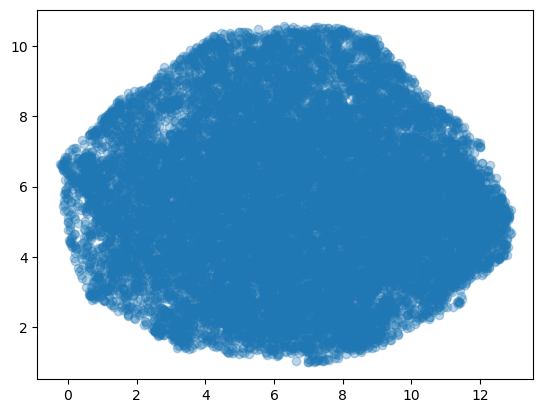

In [7]:
specs /= specs.max(axis=1, keepdims=True)  # relative to loudest harmonic (linear); dB conversion below
floor_db = -40 #ignore anything 100 times weaker
db = 20 * np.log10(np.maximum(specs, 10 ** (floor_db / 20)))
features = db - floor_db
reducer = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.25,
                    random_state=42, metric="euclidean")
emb_umap_fft = reducer.fit_transform(features)

plt.scatter(
    emb_umap_fft[:, 0],
    emb_umap_fft[:, 1],
    alpha = 0.3,
)

## Write data out as .bin

In [8]:
import pandas as pd
from pathlib import Path
import json

dat = pd.read_csv("../Processed_Data/Normalized_counts.csv")
dat = dat.set_index("GeneID")
dat_np = dat.to_numpy(dtype="float32")
dat_np.tofile("../Processed_Data/Normalized_counts.bin")


metadat = {}
metadat["Normalized_counts.bin"] = {
    "n": dat.shape[0],
    "d": dat.shape[1],
    "colnames": dat.columns.tolist(),
    "rownames": dat.index.tolist()
}

with open("../Processed_Data/bin_meta.json", "w") as f:
    json.dump(metadat, f)


In [9]:
dat = pd.read_csv("../Processed_Data/VST.csv")
dat = dat.set_index("GeneID")
dat_np = dat.to_numpy(dtype="float32")
dat_np.tofile("../Processed_Data/VST.bin")


meta_path = Path("../Processed_Data/bin_meta.json")
meta_dat = json.loads(meta_path.read_text(encoding="utf-8"))
meta_dat["VST.bin"] = {
    "n": dat.shape[0],
    "d": dat.shape[1],
    "colnames": dat.columns.tolist(),
    "rownames": dat.index.tolist()
}

with open(str(meta_path), "w") as f:
    json.dump(meta_dat, f)


In [10]:
import json
from pathlib import Path
emb_umap.astype(np.float32).tofile("../Processed_Data/count_umap.bin")
meta_path = Path("../Processed_Data/bin_meta.json")
meta_dat = json.loads(meta_path.read_text(encoding="utf-8"))
meta_dat["count_umap.bin"] = {
    "n": emb_umap.shape[0],
    "d": emb_umap.shape[1],
    "colnames": ["x", "y"],
}

with open(str(meta_path), "w") as f:
    json.dump(meta_dat, f)

In [11]:
import json
from pathlib import Path
emb_umap_fft.astype(np.float32).tofile("../Processed_Data/fft_umap.bin")
path = Path("../Processed_Data/bin_meta.json")
data = json.loads(path.read_text(encoding="utf-8"))
data["fft_umap.bin"] = {
    "n": emb_umap_fft.shape[0],
    "d": emb_umap_fft.shape[1],
    "colnames": ["x", "y"],
}
with open("../Processed_Data/bin_meta.json", "w") as f:
    json.dump(data, f)